# Experiments on the Quantinuum emulator `reimei-E`

This notebook runs the experiments of the paper that use the emulator through Quantinuum Nexus:

1. the noise strength inferred from echo circuits,
2. the two-copy measurement of a block of the Bures metric,
3. the federated training with IID data and with a Dirichlet label partition.

**Run records.** Every cell that executes circuits ends by showing a *run record*: which program
produced the result (repository, commit, state of the working tree, entry point), when (start and end
of the cell, submission and completion of every job), and on which device (backend, device name,
error-rate multipliers, job identifiers, shots, cost).  The record is also saved as JSON next to the
results.  The commit is logged at the moment a job is submitted.

**Cache.** The shot tables of finished jobs are stored in the `results/` folders of this repository.
A cell whose results are all in the cache submits nothing and needs no login; its record then lists the
jobs that produced the cached results, with their original submission times and commits.

**No accidental jobs.** Every cell below passes `--cached-only`: it reads the cache and stops with an
error if a result is missing.  To repeat a measurement on the emulator, remove its cache folder, log in
with `qnx login`, remove `--cached-only` from the cell, and run it again.

In [1]:
import os, pathlib
REPO = pathlib.Path.cwd() if (pathlib.Path.cwd() / "qfedqgt").is_dir() else pathlib.Path.cwd().parent
os.chdir(REPO)                       # the scripts write to results/ relative to the repository root

from qfedqgt import provenance
info = provenance.program_info()
print("repository :", info["repository"])
print("commit     :", info["commit"])
print("modified   :", info["modified"] or "nothing (clean working tree)")

repository : https://github.com/HarukiEmori/qfl-qgt
commit     : 8397c762bb60b9270e86cede1e543fcb1df6584e
modified   : nothing (clean working tree)


## 0. Login check (only needed before a cell that submits jobs)

The check reports whether the stored Nexus login is valid.  It does not print the account.

In [2]:
from qfedqgt.nexus import login_status
print(login_status())

Nexus login: valid


## 1. Noise strength from echo circuits

The echo circuit `U` followed by `U^dagger` returns the all-zero outcome with a probability equal to the
purity of the state for global depolarizing noise.  The first cell uses the two-layer circuit of the
simulations, the second the one-layer circuit of the emulator experiment.

In [3]:
%run scripts/nexus_geometry.py --device reimei-E --scales 1 50 150 200 300 500 --shots 100 --cached-only

x1     survival 0.986+/-0.004 (local model 0.985)  p_hat 0.007 (local 0.008)


x50    survival 0.481+/-0.018 (local model 0.543)  p_hat 0.332 (local 0.284)


x150   survival 0.142+/-0.012 (local model 0.191)  p_hat 0.708 (local 0.629)


x200   survival 0.089+/-0.010 (local model 0.131)  p_hat 0.833 (local 0.730)


x300   survival 0.045+/-0.007 (local model 0.083)  p_hat 1.000 (local 0.853)


x500   survival 0.025+/-0.006 (local model 0.065)  p_hat 1.000 (local 0.951)


replay from the cache: results/nexus-geometry/reimei-E.json is reproduced


Program,task,noise strength from echo circuits
,entry point,scripts/nexus_geometry.py
,repository,https://github.com/HarukiEmori/qfl-qgt
,commit,8397c762bb60b9270e86cede1e543fcb1df6584e
,working tree,clean
When,started,2026-11-19T10:39:17-0800
,finished,2026-11-19T10:39:18-0800
,duration,0 s
,jobs submitted from,2026-11-19T00:16:24-0800
,last job completed,2026-11-19T00:22:42-0800
Device,kind,Quantinuum Nexus


In [4]:
%run scripts/nexus_geometry.py --device reimei-E --scenario emulator_iid --scales 1 100 200 300 400 500 --shots 100 --cached-only

x1     survival 0.985+/-0.004 (local model 0.991)  p_hat 0.008 (local 0.005)


x100   survival 0.471+/-0.018 (local model 0.533)  p_hat 0.340 (local 0.291)


x200   survival 0.236+/-0.015 (local model 0.290)  p_hat 0.569 (local 0.507)


x300   survival 0.124+/-0.012 (local model 0.169)  p_hat 0.744 (local 0.664)


x400   survival 0.072+/-0.009 (local model 0.110)  p_hat 0.897 (local 0.775)


x500   survival 0.045+/-0.007 (local model 0.082)  p_hat 1.000 (local 0.855)


replay from the cache: results/nexus-geometry/reimei-E-emulator_iid.json is reproduced


Program,task,noise strength from echo circuits
,entry point,scripts/nexus_geometry.py
,repository,https://github.com/HarukiEmori/qfl-qgt
,commit,8397c762bb60b9270e86cede1e543fcb1df6584e
,working tree,clean
When,started,2026-11-19T10:39:18-0800
,finished,2026-11-19T10:39:18-0800
,duration,0 s
,jobs submitted from,2026-11-19T01:42:23-0800
,last job completed,2026-11-19T01:46:38-0800
Device,kind,Quantinuum Nexus


## 2. Two-copy measurement of the Bures metric

A destructive SWAP test on two copies of the state gives the overlaps `Tr[rho_a rho_b]`; with the
parameter-shift rule they give `Tr[(d_i rho)(d_j rho)]`, and the purity gives the factor that turns it
into the Bures metric.  The cell measures the 8 x 8 block of the second layer at one input.

In [5]:
%run scripts/nexus_metric.py --backend nexus --device reimei-E --scales 1 50 --shots 200 --layer 1 --cached-only

x1     purity 0.980 (local model 0.980, state 0.987)  Tr G 1.119+/-0.042 (local estimator 1.170, exact 1.187, noiseless 1.196)  rms dev 0.020 / se 0.015


x50    purity 0.440 (local model 0.462, state 0.527)  Tr G 0.667+/-0.085 (local estimator 0.649, exact 0.818, noiseless 1.196)  rms dev 0.032 / se 0.026


replay from the cache: results/metric/reimei-E.json is reproduced


Program,task,two-copy measurement of the Bures metric
,entry point,scripts/nexus_metric.py
,repository,https://github.com/HarukiEmori/qfl-qgt
,commit,8397c762bb60b9270e86cede1e543fcb1df6584e
,working tree,clean
When,started,2026-11-19T10:39:18-0800
,finished,2026-11-19T10:39:41-0800
,duration,23 s
,jobs submitted from,2026-11-19T01:10:49-0800
,last job completed,2026-11-19T01:37:31-0800
Device,kind,Quantinuum Nexus


## 3. Federated training on the emulator

Six seeds with IID data and the same seeds with a Dirichlet label partition were run.  The runs of a
campaign advance round by round together, and the circuits of a round are submitted at once.  Four
clients take part: two reference clients with 30 shots per circuit and two clients with 300-fold error
rates and one shot per circuit.  The step sizes were selected with the local gate-level model on
separate tuning seeds (`scripts/run_campaign.py tune --scenarios emulator_iid emulator_dirichlet`).
After the last round the models of the last five rounds are evaluated on the emulator with the
reference error rates.

The experiment was executed as one campaign: `emulator-reimei-E` (seeds 0 to 5).
The seeds and the packing of the circuits into programs are stored in `packing.json` of every result
folder and are reused by the cells below.

In [6]:
%run scripts/run_emulator.py --backend nexus --device reimei-E --name emulator-reimei-E --cached-only

round   1  noiseless accuracy, mean over the runs: QFedAvg=0.211  QFedFisher=0.215  QFedQGT=0.197  (0 s)


round   2  noiseless accuracy, mean over the runs: QFedAvg=0.235  QFedFisher=0.196  QFedQGT=0.205  (0 s)


round   3  noiseless accuracy, mean over the runs: QFedAvg=0.255  QFedFisher=0.217  QFedQGT=0.236  (0 s)


round   4  noiseless accuracy, mean over the runs: QFedAvg=0.244  QFedFisher=0.229  QFedQGT=0.262  (0 s)


round   5  noiseless accuracy, mean over the runs: QFedAvg=0.231  QFedFisher=0.219  QFedQGT=0.266  (0 s)


round   6  noiseless accuracy, mean over the runs: QFedAvg=0.280  QFedFisher=0.242  QFedQGT=0.300  (0 s)


... (20 outputs left out)

emulator_dirichlet     seed 5  QFedAvg: device 0.397 noiseless 0.363  QFedFisher: device 0.287 noiseless 0.250  QFedQGT: device 0.407 noiseless 0.390


replay from the cache: results/emulator-reimei-E/summary.json is reproduced


replay from the cache: 13 of 13 stored result files are reproduced


Program,task,federated training of several runs in lockstep
,entry point,scripts/run_emulator.py
,repository,https://github.com/HarukiEmori/qfl-qgt
,commit,8397c762bb60b9270e86cede1e543fcb1df6584e
,working tree,clean
When,started,2026-11-19T10:39:42-0800
,finished,2026-11-19T10:39:43-0800
,duration,1 s
,jobs submitted from,2026-11-19T03:26:58-0800
,last job completed,2026-11-19T10:10:42-0800
Device,kind,Quantinuum Nexus


## 4. Summary of the training

`device` is the test accuracy measured on the emulator (mean over the last five rounds), and `noiseless`
is the accuracy of the noiseless circuit with the same parameters.  The differences are QFedQGT minus the
baseline in percentage points with the standard error of the paired difference.

In [7]:
%run scripts/emulator_summary.py

IID data: 6 seeds
  QFedAvg     device 0.321 +/- 0.042   noiseless 0.323 +/- 0.044
  QFedFisher  device 0.273 +/- 0.021   noiseless 0.314 +/- 0.030
  QFedQGT     device 0.391 +/- 0.038   noiseless 0.416 +/- 0.045
  QFedQGT - QFedAvg     (device   )  +7.0 +/-  5.3 points, higher in  4 of 6 seeds
  QFedQGT - QFedAvg     (noiseless)  +9.4 +/-  3.1 points, higher in  6 of 6 seeds
  QFedQGT - QFedFisher  (device   ) +11.7 +/-  5.3 points, higher in  5 of 6 seeds
  QFedQGT - QFedFisher  (noiseless) +10.3 +/-  6.5 points, higher in  4 of 6 seeds
Dirichlet partition: 6 seeds
  QFedAvg     device 0.298 +/- 0.026   noiseless 0.287 +/- 0.029
  QFedFisher  device 0.322 +/- 0.014   noiseless 0.280 +/- 0.026
  QFedQGT     device 0.352 +/- 0.034   noiseless 0.387 +/- 0.035
  QFedQGT - QFedAvg     (device   )  +5.4 +/-  3.1 points, higher in  6 of 6 seeds
  QFedQGT - QFedAvg     (noiseless) +10.0 +/-  5.2 points, higher in  6 of 6 seeds
  QFedQGT - QFedFisher  (device   )  +2.9 +/-  2.7 points, higher

In [8]:
%run scripts/make_figures.py emulator

wrote figures/emulator.pdf and figures/emulator.png


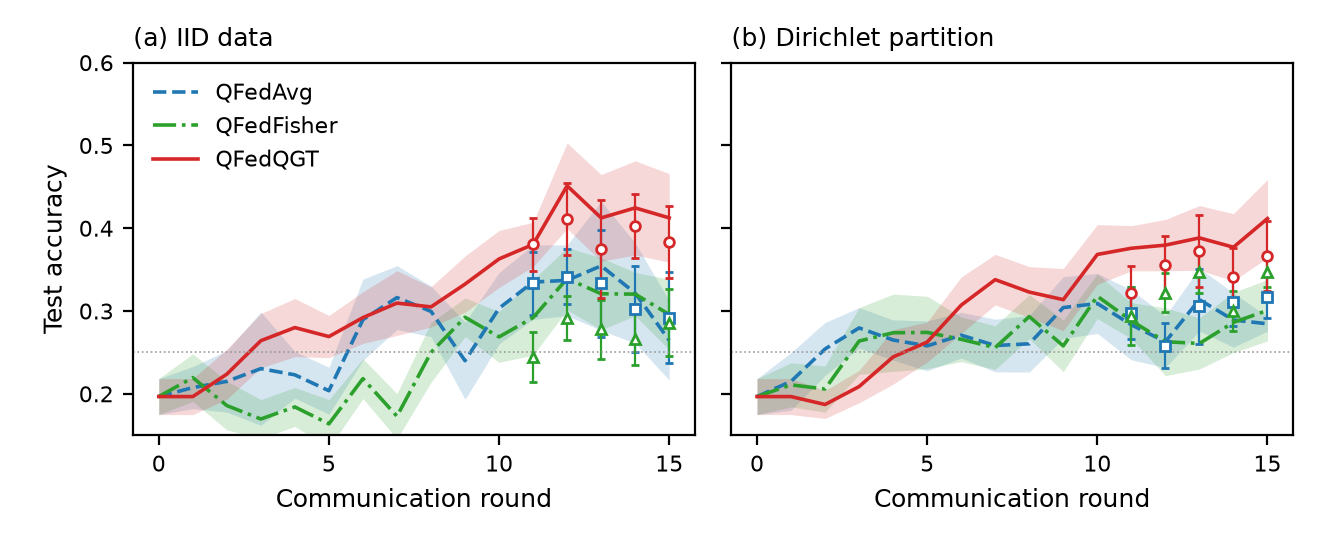

In [9]:
from IPython.display import Image
Image(filename=str(REPO / "figures" / "emulator.png"), width=700)

In [10]:
# the saved run records can be shown again at any time
provenance.load_record(str(REPO / "results" / "metric" / "reimei-E-provenance.json"))

Program,task,two-copy measurement of the Bures metric
,entry point,scripts/nexus_metric.py
,repository,https://github.com/HarukiEmori/qfl-qgt
,commit,590741b058c461fce72cc355c4228509af82f0a1
,working tree,"modified: notebooks/, scripts/nexus_metric.py"
When,started,2026-11-19T04:06:40-0800
,finished,2026-11-19T04:07:03-0800
,duration,23 s
,jobs submitted from,2026-11-19T01:10:49-0800
,last job completed,2026-11-19T01:37:31-0800
Device,kind,Quantinuum Nexus
